In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression 
from sklearn.linear_model import Ridge,Lasso
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from scipy.special import expit,softmax

In [6]:
# 데이터 생성 
wine = pd.read_csv('data/wine.csv')
print(wine.head(2))
# print(wine['alcohol'].mean())
# print(wine.columns)
# print(wine.info())     # null공백이 없는지 확인
# print(wine.describe()) # 전반적인 정보확인
# 2. data, label분리
data = wine[['alcohol', 'sugar', 'pH']].values
label = wine['class'].values


   alcohol  sugar    pH  class
0      9.4    1.9  3.51    0.0
1      9.8    2.6  3.20    0.0


In [7]:
# train데이터, test데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)


In [9]:
# 데이터 전처리 스케일 조정, 정규화 작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [10]:
# 확률적 경사하강법 함수사용 / max_iter = 10 제외 / for문으로 사용
sc = SGDClassifier(loss='log_loss', random_state=42)
train_score=[]
test_score=[]

In [15]:
# fit을 먼저 사용하지 않기에 정답을 모두 알지 못함.
# 그래서 모든 정답을 알려줘야 함.
classes = np.unique(train_label)
for _ in range(0,500):   
    # partial_fit 함수는 데이터의 일부만 전달될 수 있다고 가정하기에, 클래스(결과값)개수를 꼭 넘겨야 함.
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

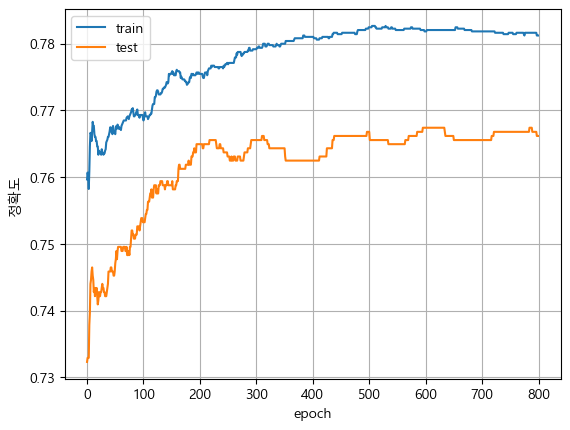

In [16]:
# plt.figure(figsize=(10,6)) #그래프 가로세로크기설정
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('epoch')
plt.ylabel('정확도')
plt.legend(['train','test'])
plt.grid()
plt.show()


In [14]:
# 30-200 사이의 그래프를 보면서, 반복횟수를 조정해서 최상의 조건을 찾음. / tol=None 조기종료 하지 않기   
sc = SGDClassifier(loss='log_loss', max_iter=300, tol=None, random_state=42)
sc.fit(train_scaled,train_label) 
print(sc.score(train_scaled,train_label))
print(sc.score(test_scaled,test_label))


0.7820197044334976
0.7661538461538462


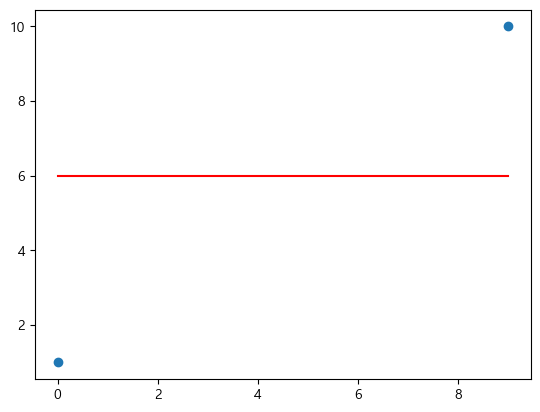

In [52]:
alist = list(range(10))
plt.scatter([0,9],[1,10])
plt.plot(alist,[6]*len(alist),color='r')
plt.show()